In [ ]:
import plotly.express as px
import pandas as pd

df = pd.read_excel('DatasetClean_actualizado.xlsx')

df.to_csv('DatasetClean.csv', index=False)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5116 entries, 0 to 5115
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   ORDEN DE LA ENTIDAD      5116 non-null   object
 1   SECTOR                   5116 non-null   object
 2   REGIÓN                   5116 non-null   object
 3   DIVIPOLA DEPARTAMENTO    5116 non-null   int64 
 4   DEPARTAMENTO             5116 non-null   object
 5   CLASIFICACIÓN TAXONOMÍA  5116 non-null   object
 6   TIPO DE INCIDENTE        5116 non-null   object
 7   IMPORTANCIA              5116 non-null   object
 8   DIA                      5116 non-null   int64 
 9   MES                      5116 non-null   object
 10  AÑO                      5116 non-null   int64 
 11  IMPORTANCIA_BINARIA      5116 non-null   object
 12  REGION_IMPORTANCIA       5116 non-null   object
dtypes: int64(3), object(10)
memory usage: 519.7+ KB


# **Añadir columna de importancia (binaria)**

In [ ]:
def clasificar_importancia(valor):
    if valor in ['Muy Grave', 'Grave']:
        return 'Importante'
    else:
        return 'No importante'

df['IMPORTANCIA_BINARIA'] = df['IMPORTANCIA'].apply(clasificar_importancia)

df['IMPORTANCIA_BINARIA'].value_counts()

,count
IMPORTANCIA_BINARIA,
No importante,3926
Importante,1190


# **Añadir columna: Region + Importancia**

In [ ]:
df['REGION_IMPORTANCIA'] = df['REGIÓN'] + ' - ' + df['IMPORTANCIA']

df['REGION_IMPORTANCIA'].value_counts()

,count
REGION_IMPORTANCIA,
Bogotá D.C. - Menor,1409
Bogotá D.C. - Solicitud,1054
Bogotá D.C. - Grave,660
Centro Oriental - Menor,231
Eje Cafetero - Menor,210
Caribe - Menor,161
Centro Sur - Menor,160
Pacífico - Menor,160
Centro Oriental - Solicitud,152


# **Creacion de graficos con Plotly**

# **- incidentes por region**

In [ ]:
df['REGIÓN'].value_counts().reset_index()

,REGIÓN,count
0,Bogotá D.C.,3161
1,Centro Oriental,486
2,Eje Cafetero,434
3,Caribe,294
4,Pacífico,285
5,Centro Sur,243
6,Llanos Orientales,208
7,Seaflower,5


In [ ]:
region_counts = df['REGIÓN'].value_counts().reset_index()
region_counts.columns = ['REGIÓN', 'CANTIDAD']

fig_region = px.bar(
    region_counts,
    x='REGIÓN',
    y='CANTIDAD',
    color='CANTIDAD',
    text='CANTIDAD',
    title='Distribución de Incidentes por Región'
)

fig_region.update_layout(title_x=0.5)
fig_region.show()

En el gráfico anterior se evidencia que la gran mayoría de los incidentes, específicamente el 61.78%, pertenecen a la región de Bogotá D.C. En comparación, la segunda región con mayor participación, Centro Oriental, representa solo el 9.49%, lo que muestra una diferencia significativa en la distribución de los datos.

# **-Top de departamentos mas afectados**

In [ ]:
df['DEPARTAMENTO'].value_counts().reset_index()

,DEPARTAMENTO,count
0,Bogotá D.C.,3161
1,Antioquia,328
2,Cundinamarca,179
3,Santander,161
4,Valle del Cauca,148
5,Casanare,111
6,Tolima,101
7,Boyacá,98
8,Nariño,74
9,Huila,66


In [ ]:
dep_counts = df['DEPARTAMENTO'].value_counts().head(10).reset_index()
dep_counts.columns = ['DEPARTAMENTO', 'CANTIDAD']

fig_dep = px.bar(
    dep_counts,
    x='DEPARTAMENTO',
    y='CANTIDAD',
    color='CANTIDAD',
    text='CANTIDAD',
    title='Top 10 Departamentos con más Incidentes'
)

fig_dep.update_layout(title_x=0.5)
fig_dep.show()

Este gráfico presenta un comportamiento similar al anterior, ya que la gran mayoría de los datos se concentra en la región de Bogotá D.C., representando el mismo 61.78% del total. Como conclusión, se puede afirmar que la mayor parte de los incidentes de ciberseguridad se concentran en la capital del país. Esto probablemente se debe a su alta actividad socioeconómica, mayor infraestructura tecnológica y concentración de usuarios.

# **-Tipos de incidentes mas frecuentes**

In [ ]:
tipo_counts = df['TIPO DE INCIDENTE'].value_counts().reset_index()
tipo_counts.columns = ['TIPO', 'CANTIDAD']

fig_tipo = px.bar(
    tipo_counts,
    x='TIPO',
    y='CANTIDAD',
    color='CANTIDAD',
    text='CANTIDAD',
    title='Tipos de Incidentes Más Frecuentes'
)

fig_tipo.update_layout(title_x=0.5)
fig_tipo.show()

En este grafico podemos saber que tipo de ataque es el más reportado, en este caso el mas frecuente es el incidente no clasificado lo que quiere decir que La mayoría de los incidentes están mal clasificados o no categorizados lo que indica mala clasificacion o problemas al registrar datos, y el phishing es el tipo de ataque mas comun y el mayor problema.

# **-Evolucion temporal**

In [ ]:
meses = {
    'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4,
    'May': 5, 'Jun': 6, 'Jul': 7, 'Aug': 8,
    'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12
}

df['MES_NUM'] = df['MES'].map(meses)

In [ ]:
import plotly.express as px

df['FECHA_MES'] = pd.to_datetime({
    'year': df['AÑO'],
    'month': df['MES_NUM'],
    'day': 1
})

# Top 5 tipos más frecuentes
top_tipos = df['TIPO DE INCIDENTE'].value_counts().head(5).index

df_filtrado = df[df['TIPO DE INCIDENTE'].isin(top_tipos)]

# Agrupar por fecha y tipo
evolucion_tipo = df_filtrado.groupby(['FECHA_MES', 'TIPO DE INCIDENTE']).size().reset_index(name='CANTIDAD')

# Gráfico
fig = px.line(
    evolucion_tipo,
    x='FECHA_MES',
    y='CANTIDAD',
    color='TIPO DE INCIDENTE',
    title='Evolución Mensual por Tipo de Incidente'
)

fig.update_layout(
    title_x=0.5,
    template='plotly_white',
    xaxis_title='Fecha',
    yaxis_title='Cantidad'
)

fig.show()

El análisis por tipo de incidente muestra comportamientos diferenciados a lo largo del tiempo. Se destacan picos significativos en phishing y en incidentes no clasificados, lo que indica tanto un aumento en ciertos tipos de ataques. Además, algunos incidentes presentan tendencias crecientes, como el uso no autorizado de recursos, lo que sugiere riesgos emergentes en la seguridad.

# **-Proporción de importancia**

In [ ]:
imp_counts = df['IMPORTANCIA_BINARIA'].value_counts().reset_index()
imp_counts.columns = ['IMPORTANCIA', 'CANTIDAD']

fig_pie = px.pie(
    imp_counts,
    names='IMPORTANCIA',
    values='CANTIDAD',
    title='Proporción de Incidentes según Importancia',
    color='IMPORTANCIA',
    color_discrete_map={
        'Importante': '#C9C3F4',
        'No importante': '#3B28D4'
    }
)

fig_pie.update_traces(
    textinfo='percent+label',
    pull=[0.05 if x == 'Importante' else 0 for x in imp_counts['IMPORTANCIA']],
    marker=dict(line=dict(color='#FFFFFF', width=2))
)

fig_pie.update_layout(
    title_x=0.5,
    legend_title='Clasificación',
    template='plotly_white'
)

fig_pie.show()

Esta gráfica de pastel permite analizar la proporción de incidentes según su nivel de importancia. Se observa que predominan los incidentes de menor importancia, lo que indica que los eventos críticos son menos frecuentes. Sin embargo, estos últimos no deben ser ignorados, ya que pueden representar riesgos significativos para la seguridad.

# **-Region vs importancia**

In [ ]:
tabla = df.groupby(['REGIÓN', 'IMPORTANCIA']).size().reset_index(name='CANTIDAD')

fig_region_imp = px.bar(
    tabla,
    x='REGIÓN',
    y='CANTIDAD',
    color='IMPORTANCIA',
    barmode='group',
    title='Incidentes por Región según Importancia'
)

fig_region_imp.update_layout(title_x=0.5)
fig_region_imp.show()

El análisis regional muestra una alta concentración de incidentes en Bogotá D.C., lo que puede estar asociado a su nivel de actividad económica y tecnológica. Además, predominan los incidentes de tipo menor en todas las regiones, mientras que los incidentes muy graves son poco frecuentes pero críticos. Esto permite identificar zonas prioritarias para la gestión de riesgos y asignación de recursos.

# **-Dashboard Interactivo de tipo de incidente por region**

In [ ]:
import plotly.graph_objects as go

regiones = df['REGIÓN'].unique()

fig_dash = go.Figure()

for region in regiones:
    df_filtrado = df[df['REGIÓN'] == region]
    conteo = df_filtrado['TIPO DE INCIDENTE'].value_counts()

    fig_dash.add_trace(go.Bar(
        x=conteo.index,
        y=conteo.values,
        name=region,
        visible=(region == regiones[0]),
        marker=dict(color='#3B28D4'),
        text=conteo.values,
        textposition='outside'
    ))

buttons = []

for i, region in enumerate(regiones):
    visible = [False] * len(regiones)
    visible[i] = True

    buttons.append(dict(
        label=region,
        method="update",
        args=[{"visible": visible},
              {"title": f"Tipos de Incidente en {region}"}]
    ))

fig_dash.update_layout(
    updatemenus=[dict(
        active=0,
        buttons=buttons,
        x=1.15,
        y=1
    )],
    title='Dashboard Interactivo de Incidentes por Región',
    title_x=0.5,
    template='plotly_white',
    xaxis_title='Tipo de Incidente',
    yaxis_title='Cantidad',
    showlegend=False
)

fig_dash.show()

Este dashboard interactivo permite visualizar de manera clara los tipos de incidentes para cada región de forma independiente. Aunque los valores varían según la región seleccionada, se evidencia una tendencia general en la predominancia de incidentes no clasificados, phishing y uso no autorizado de recursos. Asimismo, en algunas regiones se observa una mayor presencia de otros tipos de incidentes, como el compromiso de aplicaciones, lo que refleja diferencias en los patrones de riesgo según la zona.

## Modelo de clasificación

importación de librerias y preparar datos

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
import xgboost as xgb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

scaler = StandardScaler()

print("Valores únicos en IMPORTANCIA:")
print(df['IMPORTANCIA'].value_counts())
print("\n" + "="*50 + "\n")

columnas = ['ORDEN DE LA ENTIDAD', 'SECTOR', 'REGIÓN',
            'DEPARTAMENTO', 'CLASIFICACIÓN TAXONOMÍA',
            'TIPO DE INCIDENTE', 'DIA', 'MES', 'AÑO'
            ]

df_ml = df[columnas + ['IMPORTANCIA']].copy()
df_ml = df_ml.dropna(subset=['IMPORTANCIA'])

print(f"Dataset listo: {df_ml.shape[0]} filas, {df_ml.shape[1]} columnas")

Valores únicos en IMPORTANCIA:
IMPORTANCIA
Menor        2432
Solicitud    1494
Grave        1141
Muy Grave      49
Name: count, dtype: int64


Dataset listo: 5116 filas, 10 columnas


Codificar y dividir datos

In [ ]:
label_encoders = {}
for col in df_ml.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    df_ml[col] = le.fit_transform(df_ml[col].astype(str))
    label_encoders[col] = le

X = df_ml.drop('IMPORTANCIA', axis=1)
y = df_ml['IMPORTANCIA']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

categoria_nombres = list(label_encoders['IMPORTANCIA'].classes_)
print(f"Entrenamiento: {X_train.shape[0]} filas")
print(f"Prueba: {X_test.shape[0]} filas")
print(f"Categorías a predecir: {y.nunique()}")
print(f"Nombres de categorías: {categoria_nombres}")

Entrenamiento: 4092 filas
Prueba: 1024 filas
Categorías a predecir: 4
Nombres de categorías: ['Grave', 'Menor', 'Muy Grave', 'Solicitud']


Entrenar modelos y comparar

In [ ]:
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
precision_rf = accuracy_score(y_test, y_pred_rf)

xgb_model = xgb.XGBClassifier(n_estimators=100, max_depth=10, learning_rate=0.1,
                              random_state=42, eval_metric='mlogloss')
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
precision_xgb = accuracy_score(y_test, y_pred_xgb)

print("Resultados de los modelos:")
print(f"Random Forest: {precision_rf*100:.2f}%")
print(f"XGBoost: {precision_xgb*100:.2f}%")

if precision_xgb >= precision_rf:
    mejor_modelo = xgb_model
    mejor_pred = y_pred_xgb
    print(f"\nEl mejor modelo es: XGBoost con {precision_xgb*100:.2f}%")
else:
    mejor_modelo = rf
    mejor_pred = y_pred_rf
    print(f"\nEl mejor modelo es: Random Forest con {precision_rf*100:.2f}%")

Resultados de los modelos:
Random Forest: 89.84%
XGBoost: 91.02%

El mejor modelo es: XGBoost con 91.02%


Matriz de confusión y características importantes

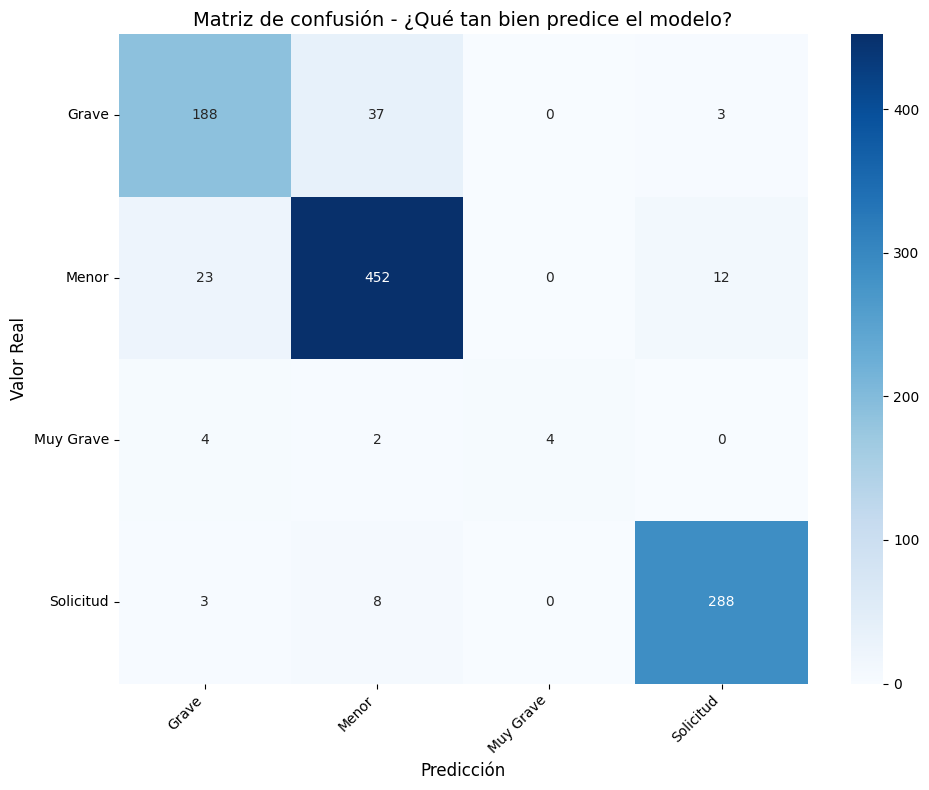


Reporte de clasificación:
              precision    recall  f1-score   support

       Grave       0.86      0.82      0.84       228
       Menor       0.91      0.93      0.92       487
   Muy Grave       1.00      0.40      0.57        10
   Solicitud       0.95      0.96      0.96       299

    accuracy                           0.91      1024
   macro avg       0.93      0.78      0.82      1024
weighted avg       0.91      0.91      0.91      1024


Las 5 características más importantes:
1. CLASIFICACIÓN TAXONOMÍA: 0.6988
2. TIPO DE INCIDENTE: 0.1282
3. AÑO: 0.0716
4. MES: 0.0229
5. DIA: 0.0165


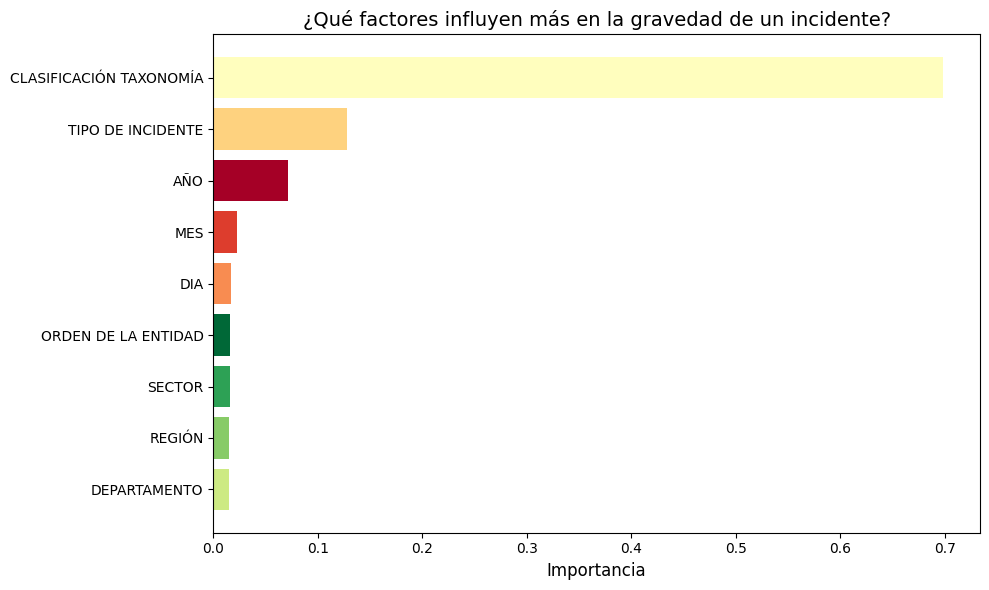


Modelo listo para predecir nuevos incidentes


In [ ]:
cm = confusion_matrix(y_test, mejor_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=categoria_nombres,
            yticklabels=categoria_nombres)
plt.title("Matriz de confusión - ¿Qué tan bien predice el modelo?", fontsize=14)
plt.xlabel('Predicción', fontsize=12)
plt.ylabel('Valor Real', fontsize=12)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("\nReporte de clasificación:")
print(classification_report(y_test, mejor_pred, target_names=categoria_nombres))

importancia = mejor_modelo.feature_importances_
caracteristicas = X.columns
indices = np.argsort(importancia)[::-1]

print("\nLas 5 características más importantes:")
print("="*40)
for i in range(min(5, len(caracteristicas))):
    print(f"{i+1}. {caracteristicas[indices[i]]}: {importancia[indices[i]]:.4f}")

plt.figure(figsize=(10, 6))
colors = plt.cm.RdYlGn_r(np.linspace(0, 1, len(importancia)))
plt.barh(range(len(importancia)), importancia[indices], color=colors[indices])
plt.yticks(range(len(importancia)), [caracteristicas[i] for i in indices])
plt.xlabel('Importancia', fontsize=12)
plt.title('¿Qué factores influyen más en la gravedad de un incidente?', fontsize=14)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\nModelo listo para predecir nuevos incidentes")

Incidentes nuevos para probar el funcionamiento del modelo

In [ ]:
columnas_clustering = ['ORDEN DE LA ENTIDAD', 'SECTOR', 'REGIÓN',
                       'DEPARTAMENTO', 'CLASIFICACIÓN TAXONOMÍA',
                       'TIPO DE INCIDENTE', 'DIA', 'MES', 'AÑO']

df_cluster_temp = df[columnas_clustering].copy()
df_cluster_temp = df_cluster_temp.dropna()

label_cluster_temp = {}
for col in df_cluster_temp.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    df_cluster_temp[col] = le.fit_transform(df_cluster_temp[col].astype(str))
    label_cluster_temp[col] = le

datos_escalados_temp = scaler.fit_transform(df_cluster_temp)
kmeans_global = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_global.fit(datos_escalados_temp)

nuevo_incidente = {
    'ORDEN DE LA ENTIDAD': 'Privada',
    'SECTOR': 'privado',
    'REGIÓN': 'Bogotá D.C.',
    'DEPARTAMENTO': 'Bogotá D.C.',
    'CLASIFICACIÓN TAXONOMÍA': 'Fraude',
    'TIPO DE INCIDENTE': 'phishing',
    'DIA': 4,
    'MES': 'May',
    'AÑO': 2026
}

nuevo_df = pd.DataFrame([nuevo_incidente])

for col in nuevo_df.columns:
    if col in label_encoders:
        if nuevo_df[col].iloc[0] in label_encoders[col].classes_:
            nuevo_df[col] = label_encoders[col].transform(nuevo_df[col])
        else:
            print(f"Advertencia: {col}={nuevo_df[col].iloc[0]} no encontrado, usando valor por defecto")
            nuevo_df[col] = 0
for col in X.columns:
    if col not in nuevo_df.columns:
        nuevo_df[col] = 0
nuevo_df = nuevo_df[X.columns]

prediccion_num = mejor_modelo.predict(nuevo_df)[0]
prediccion = categoria_nombres[prediccion_num]

print("="*50)
print("Predicción para un nuevo incidente")
print("="*50)
print("Características del incidente:")
for key, value in nuevo_incidente.items():
    print(f"  {key}: {value}")
print(f"\nEl incidente es: {prediccion}")

if prediccion == 'Muy Grave':
    print("¡ATENCIÓN! Incidente de máxima gravedad, prioridad absoluta.")
elif prediccion == 'Grave':
    print("Incidente grave, requiere atención prioritaria.")
elif prediccion == 'Menor':
    print("Incidente menor, puede esperar.")
else:
    print("Solo una solicitud de información, sin peligro real.")

nuevo_df_cluster = pd.DataFrame([nuevo_incidente])
for col in nuevo_df_cluster.columns:
    if col in label_cluster_temp:
        if nuevo_df_cluster[col].iloc[0] in label_cluster_temp[col].classes_:
            nuevo_df_cluster[col] = label_cluster_temp[col].transform(nuevo_df_cluster[col])
        else:
            nuevo_df_cluster[col] = 0

for col in df_cluster_temp.columns:
    if col not in nuevo_df_cluster.columns:
        nuevo_df_cluster[col] = 0
nuevo_df_cluster = nuevo_df_cluster[df_cluster_temp.columns]

nuevo_escalado = scaler.transform(nuevo_df_cluster)
cluster_asignado = kmeans_global.predict(nuevo_escalado)[0]
print(f"El nuevo incidente pertenece al cluster: {cluster_asignado}")

Predicción para un nuevo incidente
Características del incidente:
  ORDEN DE LA ENTIDAD: Privada
  SECTOR: privado
  REGIÓN: Bogotá D.C.
  DEPARTAMENTO: Bogotá D.C.
  CLASIFICACIÓN TAXONOMÍA: Fraude
  TIPO DE INCIDENTE: phishing
  DIA: 4
  MES: May
  AÑO: 2026

El incidente es: Menor
Incidente menor, puede esperar.
El nuevo incidente pertenece al cluster: 0


## Clustering

Preparar datos para clustering

In [ ]:
columnas_clustering = ['ORDEN DE LA ENTIDAD', 'SECTOR', 'REGIÓN',
                       'DEPARTAMENTO', 'CLASIFICACIÓN TAXONOMÍA',
                       'TIPO DE INCIDENTE', 'DIA', 'MES', 'AÑO']

df_cluster = df[columnas_clustering].copy()
df_cluster = df_cluster.dropna()
print(f"Datos para clustering: {df_cluster.shape[0]} filas, {df_cluster.shape[1]} columnas")

label_cluster = {}
for col in df_cluster.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    df_cluster[col] = le.fit_transform(df_cluster[col].astype(str))
    label_cluster[col] = le

Datos para clustering: 5116 filas, 9 columnas


Escalar datos y encontrar el número óptimo de clusters (Método del Codo)

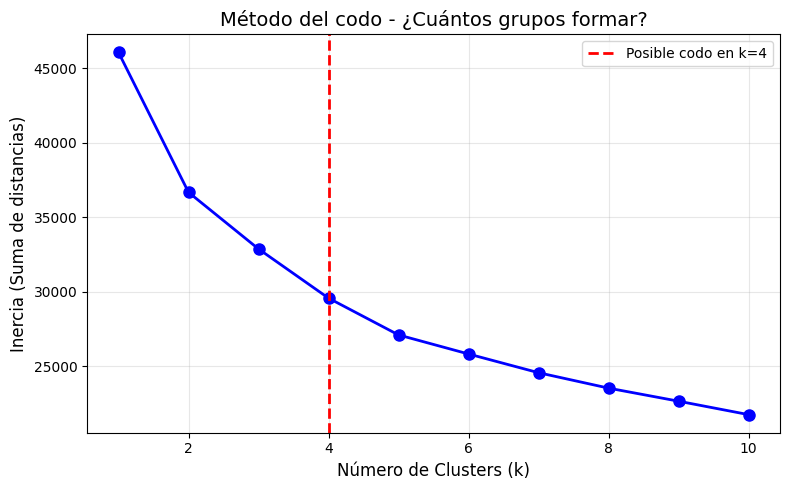

DISTRIBUCIÓN DE INCIDENTES POR CLUSTER
Cluster 0: 2149 incidentes
Cluster 1: 978 incidentes
Cluster 2: 889 incidentes
Cluster 3: 1100 incidentes


¿QUÉ TIPO DE INCIDENTES HAY EN CADA CLUSTER?

CLUSTER 0
Total: 2149 incidentes

Distribución por importancia:
IMPORTANCIA
Menor        1098
Solicitud     585
Grave         441
Muy Grave      25
Name: count, dtype: int64



CLUSTER 1
Total: 978 incidentes

Distribución por importancia:
IMPORTANCIA
Menor        836
Grave        100
Solicitud     34
Muy Grave      8
Name: count, dtype: int64



CLUSTER 2
Total: 889 incidentes

Distribución por importancia:
IMPORTANCIA
Solicitud    402
Grave        340
Menor        145
Muy Grave      2
Name: count, dtype: int64



CLUSTER 3
Total: 1100 incidentes

Distribución por importancia:
IMPORTANCIA
Solicitud    473
Menor        353
Grave        260
Muy Grave     14
Name: count, dtype: int64




In [ ]:
datos_escalados = scaler.fit_transform(df_cluster)

inercias = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(datos_escalados)
    inercias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inercias, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Número de Clusters (k)', fontsize=12)
plt.ylabel('Inercia (Suma de distancias)', fontsize=12)
plt.title('Método del codo - ¿Cuántos grupos formar?', fontsize=14)
plt.axvline(x=4, color='red', linestyle='--', linewidth=2, label='Posible codo en k=4')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

k_elegido = 4
kmeans = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
df_cluster['CLUSTER'] = kmeans.fit_predict(datos_escalados)

df_cluster['IMPORTANCIA'] = df['IMPORTANCIA'].values[:len(df_cluster)]

print("="*50)
print("DISTRIBUCIÓN DE INCIDENTES POR CLUSTER")
print("="*50)
for i in range(k_elegido):
    print(f"Cluster {i}: {len(df_cluster[df_cluster['CLUSTER']==i])} incidentes")

print("\n")
print("="*50)
print("¿QUÉ TIPO DE INCIDENTES HAY EN CADA CLUSTER?")
print("="*50)

for i in range(k_elegido):
    print(f"\n{'='*40}")
    print(f"CLUSTER {i}")
    print(f"{'='*40}")
    datos_cluster = df_cluster[df_cluster['CLUSTER'] == i]
    print(f"Total: {len(datos_cluster)} incidentes")
    print("\nDistribución por importancia:")
    print(datos_cluster['IMPORTANCIA'].value_counts())
    print("\n")

Caracteristicas de cada cluster

In [ ]:
df_cluster_texto = df[columnas_clustering].copy()
df_cluster_texto = df_cluster_texto.iloc[:len(df_cluster)]
df_cluster_texto['CLUSTER'] = df_cluster['CLUSTER'].values

print("="*50)
print("PERFIL DE CADA CLUSTER (características más comunes)")
print("="*50)

for i in range(k_elegido):
    print(f"\n{'='*40}")
    print(f"CLUSTER {i}")
    print(f"{'='*40}")
    cluster_data = df_cluster_texto[df_cluster_texto['CLUSTER'] == i]

    print(f"Total de incidentes: {len(cluster_data)}")

    region_comun = cluster_data['REGIÓN'].mode()[0] if len(cluster_data['REGIÓN'].mode()) > 0 else "N/A"
    print(f"Región más común: {region_comun}")

    taxonomia_comun = cluster_data['CLASIFICACIÓN TAXONOMÍA'].mode()[0] if len(cluster_data['CLASIFICACIÓN TAXONOMÍA'].mode()) > 0 else "N/A"
    print(f"Taxonomía más común: {taxonomia_comun}")

    tipo_comun = cluster_data['TIPO DE INCIDENTE'].mode()[0] if len(cluster_data['TIPO DE INCIDENTE'].mode()) > 0 else "N/A"
    print(f"Tipo de incidente más común: {tipo_comun}")

    sector_comun = cluster_data['SECTOR'].mode()[0] if len(cluster_data['SECTOR'].mode()) > 0 else "N/A"
    print(f"Sector más común: {sector_comun}")

PERFIL DE CADA CLUSTER (características más comunes)

CLUSTER 0
Total de incidentes: 2149
Región más común: Bogotá D.C.
Taxonomía más común: Fraude
Tipo de incidente más común: phishing
Sector más común: privado

CLUSTER 1
Total de incidentes: 978
Región más común: Centro Oriental
Taxonomía más común: Fraude
Tipo de incidente más común: uso no autorizado de recursos
Sector más común: planeación

CLUSTER 2
Total de incidentes: 889
Región más común: Centro Oriental
Taxonomía más común: Otros
Tipo de incidente más común: incidente no clasificado
Sector más común: planeación

CLUSTER 3
Total de incidentes: 1100
Región más común: Bogotá D.C.
Taxonomía más común: Otros
Tipo de incidente más común: incidente no clasificado
Sector más común: hacienda y crédito público


## Modelo PCA

Aplicar PCA y crear gráfico

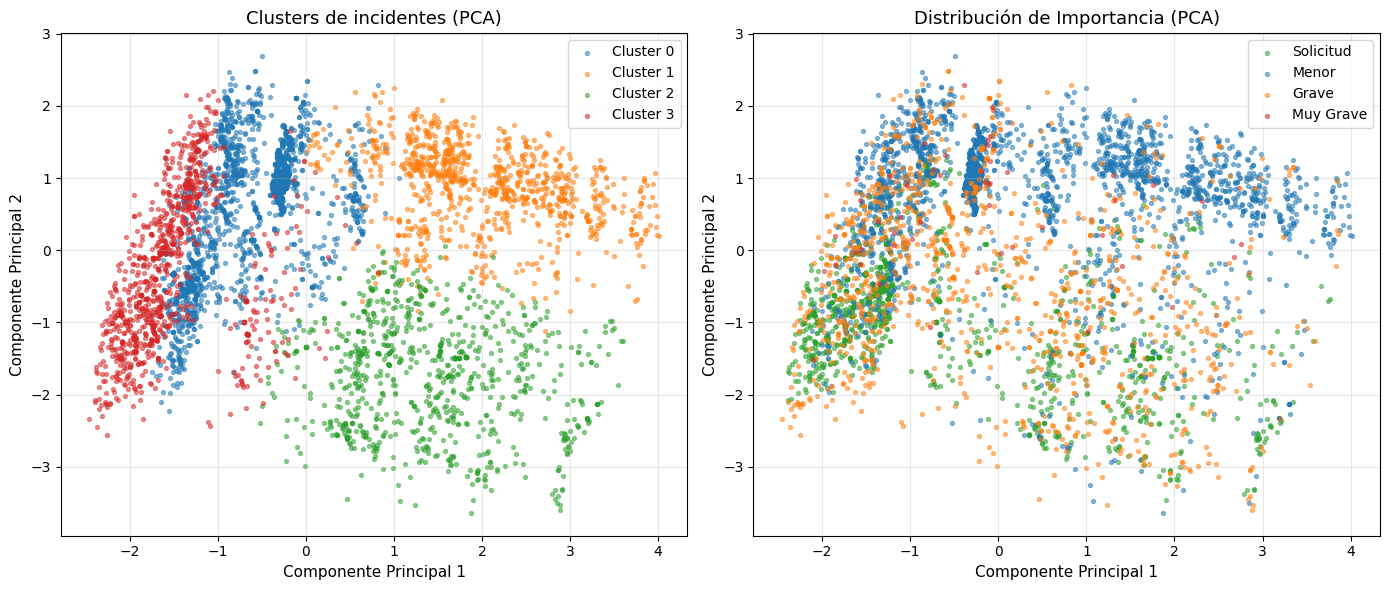

Varianza explicada por PCA1: 25.7%
Varianza explicada por PCA2: 16.6%
Total de información visualizada: 42.3%


In [ ]:
pca = PCA(n_components=2, random_state=42)
componentes_pca = pca.fit_transform(datos_escalados)

df_pca = pd.DataFrame()
df_pca['PCA1'] = componentes_pca[:, 0]
df_pca['PCA2'] = componentes_pca[:, 1]
df_pca['CLUSTER'] = df_cluster['CLUSTER'].values
df_pca['IMPORTANCIA'] = df_cluster['IMPORTANCIA'].values

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
colores = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
for i in range(k_elegido):
    datos = df_pca[df_pca['CLUSTER'] == i]
    plt.scatter(datos['PCA1'], datos['PCA2'], c=colores[i],
                label=f'Cluster {i}', alpha=0.5, s=8)
plt.xlabel('Componente Principal 1', fontsize=11)
plt.ylabel('Componente Principal 2', fontsize=11)
plt.title('Clusters de incidentes (PCA)', fontsize=13)
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
importancia_colores = {'Solicitud': '#2ca02c', 'Menor': '#1f77b4',
                        'Grave': '#ff7f0e', 'Muy Grave': '#d62728'}
for imp, color in importancia_colores.items():
    datos = df_pca[df_pca['IMPORTANCIA'] == imp]
    plt.scatter(datos['PCA1'], datos['PCA2'], c=color,
                label=imp, alpha=0.5, s=8)
plt.xlabel('Componente Principal 1', fontsize=11)
plt.ylabel('Componente Principal 2', fontsize=11)
plt.title('Distribución de Importancia (PCA)', fontsize=13)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Varianza explicada por PCA1: {pca.explained_variance_ratio_[0]*100:.1f}%")
print(f"Varianza explicada por PCA2: {pca.explained_variance_ratio_[1]*100:.1f}%")
print(f"Total de información visualizada: {sum(pca.explained_variance_ratio_)*100:.1f}%")

Ver centroides de los clusters y grafico de varianza



CENTROS DE LOS CLUSTERS (en espacio PCA)
Cluster 0: PCA1=-0.71, PCA2=0.49
Cluster 1: PCA1=2.01, PCA2=0.87
Cluster 2: PCA1=1.41, PCA2=-1.72
Cluster 3: PCA1=-1.54, PCA2=-0.34


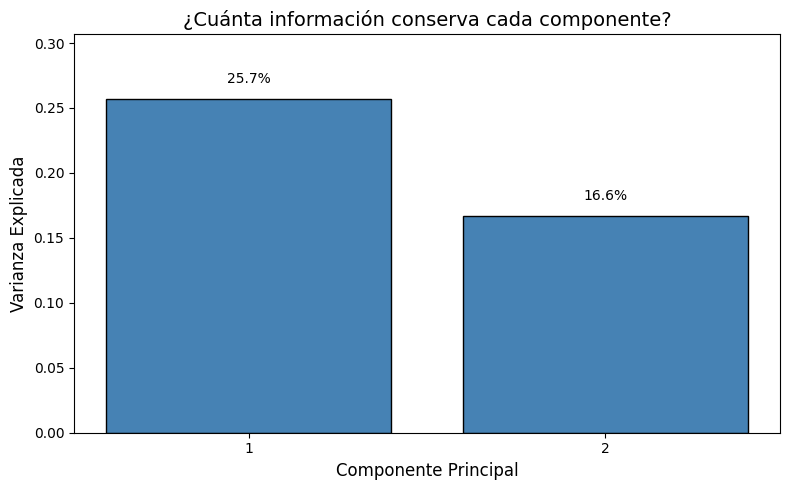

In [ ]:
print("\n" + "="*50)
print("CENTROS DE LOS CLUSTERS (en espacio PCA)")
print("="*50)
centroides_pca = pca.transform(kmeans.cluster_centers_)
for i in range(k_elegido):
    print(f"Cluster {i}: PCA1={centroides_pca[i, 0]:.2f}, PCA2={centroides_pca[i, 1]:.2f}")

plt.figure(figsize=(8, 5))
bars = plt.bar(range(1, len(pca.explained_variance_ratio_)+1),
                pca.explained_variance_ratio_,
                color='steelblue', edgecolor='black')
plt.xlabel('Componente Principal', fontsize=12)
plt.ylabel('Varianza Explicada', fontsize=12)
plt.title('¿Cuánta información conserva cada componente?', fontsize=14)
plt.xticks(range(1, len(pca.explained_variance_ratio_)+1))

for i, (bar, var) in enumerate(zip(bars, pca.explained_variance_ratio_)):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{var*100:.1f}%', ha='center', va='bottom', fontsize=10)

plt.ylim(0, max(pca.explained_variance_ratio_) + 0.05)
plt.tight_layout()
plt.show()